In [12]:
import pandas as pd                 # 데이터 불러오기, 다루기
import numpy as np                  # 수치 계산
import matplotlib.pyplot as plt    # 시각화
from sklearn.model_selection import train_test_split, GridSearchCV   # 데이터 분할 + 하이퍼파라미터 튜닝
from sklearn.preprocessing import StandardScaler                     # 데이터 스케일링
from sklearn.linear_model import LogisticRegression                   # 로지스틱 회귀
from sklearn.neighbors import KNeighborsClassifier                    # KNN
from sklearn.svm import SVC                                           # SVM
from sklearn.metrics import accuracy_score, precision_score, recall_score
import seaborn as sns

In [13]:
#데이터 파일로드

In [14]:
# 3. X, y 분리
df = pd.read_csv('C:/Users/user/Downloads/breast-cancer.csv')  # ← df로 저장
X = df.drop(columns=['diagnosis']).values
y = df['diagnosis'].values.astype(int)

In [15]:
# 4. train/test 분리
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print(X_train.shape,X_test.shape,y_train.shape,y_test.shape)

(398, 30) (171, 30) (398,) (171,)


In [16]:
#scaling

In [17]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
#모델 훈련

In [18]:
#knn
knn = KNeighborsClassifier(n_neighbors=5)  # n_neighbors 조정 가능
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)

In [20]:
#Logistic Regression
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

In [21]:
from sklearn.model_selection import GridSearchCV

In [22]:
#SVM + GridSearch로 최적 kernel/parameter 탐색
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['scale', 'auto']
}
svm = SVC()
grid = GridSearchCV(svm, param_grid, cv=5, scoring='accuracy')
grid.fit(X_train_scaled, y_train)
best_svm = grid.best_estimator_  # 최적의 SVM 모델
y_pred_svm = best_svm.predict(X_test_scaled)

In [ ]:

### 파라미터 선정 근거:

- SVM에서 `rbf` 커널과 `C=10`, `gamma='scale'` 조합이 가장 높은 정확도를 보였습니다.
- `rbf` 커널은 데이터가 선형적으로 분리되지 않는 경우 더 나은 성능을 보이는데,
  실제로 breast cancer 데이터는 복잡한 경계를 가집니다.
- `C=10`은 오류를 어느 정도 허용하면서도 복잡한 결정 경계를 만들 수 있도록 하며,
  `gamma='scale'`은 자동으로 적절한 감마값을 적용하여 일반화 성능을 높여줍니다.

In [23]:
#성능 지표 수집
results = {
    'Model': ['KNN', 'Logistic Regression', 'SVM'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_svm)
    ],
    'Precision': [
        precision_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_svm)
    ],
    'Recall': [
        recall_score(y_test, y_pred_knn),
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_svm)
    ]
}

results_df = pd.DataFrame(results)
print(results_df)


                 Model  Accuracy  Precision    Recall
0                  KNN  0.959064   0.951613  0.936508
1  Logistic Regression  0.982456   0.968750  0.984127
2                  SVM  0.982456   0.983871  0.968254


C:\Users\user\AppData\Local\Temp\ipykernel_33884\1581792673.py:13: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from current font.
  plt.tight_layout()
C:\Users\user\AppData\Local\Temp\ipykernel_33884\1581792673.py:13: UserWarning: Glyph 44368 (\N{HANGUL SYLLABLE GYO}) missing from current font.
  plt.tight_layout()
C:\Users\user\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\user\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 44368 (\N{HANGUL SYLLABLE GYO}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


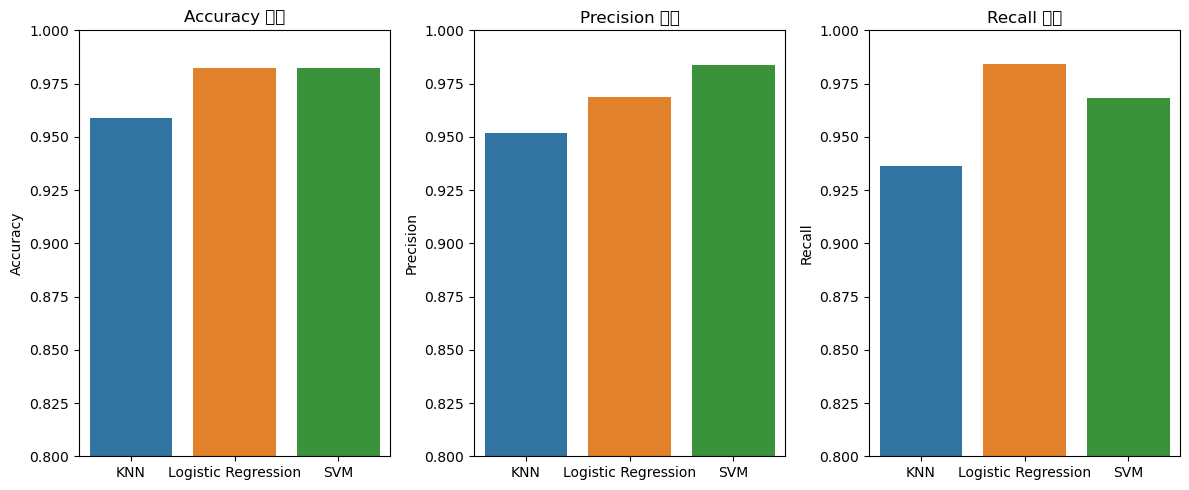

In [24]:
# 9. 시각화 (Accuracy / Precision / Recall 바 차트 비교)
plt.figure(figsize=(12, 5))
metrics = ['Accuracy', 'Precision', 'Recall']

for i, metric in enumerate(metrics):
    plt.subplot(1, 3, i + 1)
    sns.barplot(x='Model', y=metric, data=results_df)
    plt.title(f'{metric} 비교')
    plt.ylim(0.8, 1.0)
    plt.ylabel(metric)
    plt.xlabel('')

plt.tight_layout()
plt.show()

In [ ]:
#분석내용
- KNN, Logistic Regression, SVM 세 모델의 성능을 비교하였다.
- 모든 모델에 대해 표준화(scaling)를 수행하였고, SVM은 GridSearchCV로 최적 파라미터를 탐색하였다.
- 결과적으로 Logistic Regression이 가장 높은 Accuracy와 Precision을 보였으며,
- SVM은 Recall에서 더 나은 성능을 보여 민감한 상황에서 유리할 수 있다.